# 03 · Modelado predictivo

Regresión Lineal Múltiple · Pronóstico de precios a un mes · La Terminal.

## 1. Configuración y carga

In [1]:
import os
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Ubicamos los datos preparados y las carpetas de resultados y modelos.
try:
    from google.colab import drive
    drive.mount('/content/drive')
    RAIZ = Path('/content/drive/MyDrive/MAGA_Analisis_Fase2')
except ImportError:
    RAIZ = Path(os.environ.get('MAGA_PROJECT_DIR', Path.cwd() / 'MAGA_Analisis_Fase2'))

ENTRADA = RAIZ / 'data/prepared/maga_precios_mensuales_la_terminal_1998_2026.csv'
SALIDA = RAIZ / 'outputs/03_modelado_predictivo'
MODELOS = RAIZ / 'models'
SALIDA.mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(parents=True, exist_ok=True)
# Mantenemos los mismos nombres de productos que en el Notebook 02.
NOMBRES = {
    'Tomate de cocina, grande, de primera': 'Tomate',
    'Papa Loman, lavada, grande, de primera': 'Papa Loman',
    'Chile Pimiento, grande, de primera': 'Chile pimiento',
}
ORDEN = list(NOMBRES.values())
COLORES = {'Tomate': '#BB7979', 'Papa Loman': '#6A996A', 'Chile pimiento': '#378A94'}
FMT_Q = FuncFormatter(lambda x, pos: f'Q{x:,.0f}')
if not ENTRADA.is_file():
    raise FileNotFoundError('Ejecuta primero el Notebook 01: falta el CSV preparado.')
datos = pd.read_csv(ENTRADA, encoding='utf-8-sig', parse_dates=['Fecha'])
if len(datos) != 1029 or set(datos['Producto']) != set(NOMBRES) or datos.duplicated(['Producto', 'Fecha']).any():
    raise ValueError('Los datos no coinciden con la preparación del Notebook 01.')
if not np.isfinite(datos['Precio']).all() or (datos['Precio'] <= 0).any():
    raise ValueError('Precios faltantes o inválidos.')
datos['Producto_corto'] = datos['Producto'].map(NOMBRES)
datos = datos.sort_values(['Producto_corto', 'Fecha']).reset_index(drop=True)

def tabla(df, nombre):
    df.to_csv(SALIDA / nombre, index=False, encoding='utf-8-sig')
def grafica(fig, nombre):
    fig.savefig(SALIDA / nombre, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Mounted at /content/drive


## 2. Variables históricas y calendario

In [2]:
# Definimos las combinaciones de variables que vamos a evaluar.
CANDIDATOS = {
    'A · Reciente': ['lag_1', 'lag_2', 'lag_3'],
    'B · Reciente y anual': ['lag_1', 'lag_2', 'lag_3', 'lag_12'],
    'C · Calendario': ['lag_1', 'lag_2', 'lag_3', 'lag_12', 'mes_sin', 'mes_cos'],
    'D · Medio plazo': ['lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'mes_sin', 'mes_cos'],
}
# Creamos precios de meses anteriores y variables que representan el calendario.
rezagos = [1, 2, 3, 6, 12]
partes = []
for producto, grupo in datos.groupby('Producto_corto', sort=False):
    d = grupo.sort_values('Fecha').copy()
    for lag in rezagos:
        d[f'lag_{lag}'] = d['Precio'].shift(lag)
    angulo = 2 * np.pi * (d['Mes'] - 1) / 12
    d['mes_sin'] = np.sin(angulo)
    d['mes_cos'] = np.cos(angulo)
    partes.append(d)
modelables = pd.concat(partes, ignore_index=True).dropna(subset=['lag_12']).reset_index(drop=True)
assert len(modelables) == 993 and modelables.groupby('Producto_corto').size().eq(331).all()
assert modelables.groupby('Producto_corto')['Fecha'].min().eq(pd.Timestamp('1999-01-01')).all()
# Todos los rezagos excluyen el precio del mes que se intenta estimar.
assert all(np.allclose(d[f'lag_{lag}'].iloc[lag:], d['Precio'].shift(lag).iloc[lag:])
           for d in partes for lag in rezagos)

## 3. Selección de variables mediante validación cronológica

In [3]:
# Utilizamos 2022 y 2023 para validar sin mezclar meses futuros con el entrenamiento.
FOLDS = [
    ('2022', '2021-12-01', '2022-01-01', '2022-12-01'),
    ('2023', '2022-12-01', '2023-01-01', '2023-12-01'),
]
resultados = []
for configuracion, variables in CANDIDATOS.items():
    for producto in ORDEN:
        d = modelables.loc[modelables['Producto_corto'].eq(producto)]
        for anio, hasta, desde, fin in FOLDS:
            entrenamiento = d.loc[d['Fecha'].le(hasta)]
            validacion = d.loc[d['Fecha'].between(desde, fin)]
            assert len(validacion) == 12 and entrenamiento['Fecha'].max() < validacion['Fecha'].min()
            pred = LinearRegression().fit(entrenamiento[variables], entrenamiento['Precio']).predict(validacion[variables])
            mae = mean_absolute_error(validacion['Precio'], pred)
            mae_ref = mean_absolute_error(validacion['Precio'], validacion['lag_1'])
            resultados.append((configuracion, producto, anio, mae, mae_ref, mae / mae_ref, len(variables)))

validacion = pd.DataFrame(resultados, columns=['Configuracion', 'Producto', 'Anio', 'MAE_Q', 'MAE_referencia_Q', 'Razon_MAE', 'Variables'])
# Elegimos la misma configuración de variables para los tres productos.
comparacion = (validacion.groupby('Configuracion')
               .agg(Razon_MAE_media=('Razon_MAE', 'mean'), Variables=('Variables', 'first'))
               .sort_values(['Razon_MAE_media', 'Variables']).reset_index())
mejor = comparacion['Razon_MAE_media'].min()
ELECCION = (comparacion.loc[comparacion['Razon_MAE_media'].le(mejor + .01)]
            .sort_values(['Variables', 'Razon_MAE_media']).iloc[0]['Configuracion'])
VARIABLES = CANDIDATOS[ELECCION]
display(comparacion.round(3))
print('Configuración seleccionada:', ELECCION, VARIABLES)
tabla(validacion, '03_validacion.csv')

,Configuracion,Razon_MAE_media,Variables
0,D · Medio plazo,1.112,7
1,C · Calendario,1.152,6
2,B · Reciente y anual,1.170,4
3,A · Reciente,1.172,3


Configuración seleccionada: D · Medio plazo ['lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'mes_sin', 'mes_cos']


## 4. Entrenamiento y evaluación retrospectiva

In [4]:
# Calculamos los errores para comparar las predicciones con los precios reales.
def metricas(y, pred):
    real, est = np.asarray(y, dtype=float), np.asarray(pred, dtype=float)
    return (mean_absolute_error(real, est),
            np.sqrt(mean_squared_error(real, est)),
            100 * np.mean(np.abs(real - est) / real))

# Entrenamos una regresión por producto y la evaluamos con meses posteriores.
filas, coeficientes = [], []
for producto in ORDEN:
    d = modelables.loc[modelables['Producto_corto'].eq(producto)]
    entrenamiento = d.loc[d['Fecha'].le('2023-12-01')]
    prueba = d.loc[d['Fecha'].ge('2024-01-01')]
    assert len(entrenamiento) == 300 and len(prueba) == 31
    modelo = LinearRegression().fit(entrenamiento[VARIABLES], entrenamiento['Precio'])
    pred = modelo.predict(prueba[VARIABLES])
    for (_, fila), estimado in zip(prueba.iterrows(), pred):
        filas.append((producto, fila['Medida'], fila['Fecha'], fila['Precio'], estimado, fila['lag_1']))
    coeficientes.append({'Producto': producto, 'Intercepto': modelo.intercept_, **dict(zip(VARIABLES, modelo.coef_))})

# Reunimos las estimaciones, los precios reales y la referencia sencilla.
predicciones = pd.DataFrame(filas, columns=['Producto', 'Medida', 'Fecha', 'Precio_real_Q', 'Precio_estimado_Q', 'Referencia_Q'])
predicciones['Error_Q'] = predicciones['Precio_real_Q'] - predicciones['Precio_estimado_Q']
predicciones['Error_abs_Q'] = predicciones['Error_Q'].abs()

resultados = []
for producto in ORDEN:
    d = predicciones.loc[predicciones['Producto'].eq(producto)]
    mae, rmse, mape = metricas(d['Precio_real_Q'], d['Precio_estimado_Q'])
    mae_ref, rmse_ref, mape_ref = metricas(d['Precio_real_Q'], d['Referencia_Q'])
    resultados.append((producto, d['Medida'].iloc[0], len(d), mae, mae_ref, rmse, rmse_ref,
                       mape, mape_ref, 100 * (1 - mae / mae_ref)))
resumen = pd.DataFrame(resultados, columns=['Producto', 'Unidad', 'Meses', 'MAE_Q', 'MAE_referencia_Q',
                                         'RMSE_Q', 'RMSE_referencia_Q', 'MAPE_pct',
                                         'MAPE_referencia_pct', 'Mejora_MAE_pct'])
display(resumen.round(2))
tabla(predicciones, '03_predicciones.csv')
tabla(resumen, '03_metricas.csv')
tabla(pd.DataFrame(coeficientes), '03_coeficientes.csv')

,Producto,Unidad,Meses,MAE_Q,MAE_referencia_Q,RMSE_Q,RMSE_referencia_Q,MAPE_pct,MAPE_referencia_pct,Mejora_MAE_pct
0,Tomate,Caja (45 - 50 lb),31,32.59,46.58,54.20,65.56,18.85,29.06,30.04
1,Papa Loman,Quintal,31,43.55,47.87,64.58,65.37,11.51,12.96,9.02
2,Chile pimiento,Caja (90 -100 unidades),31,31.58,34.12,43.75,49.05,27.23,30.45,7.44


## 5. Resultados visuales

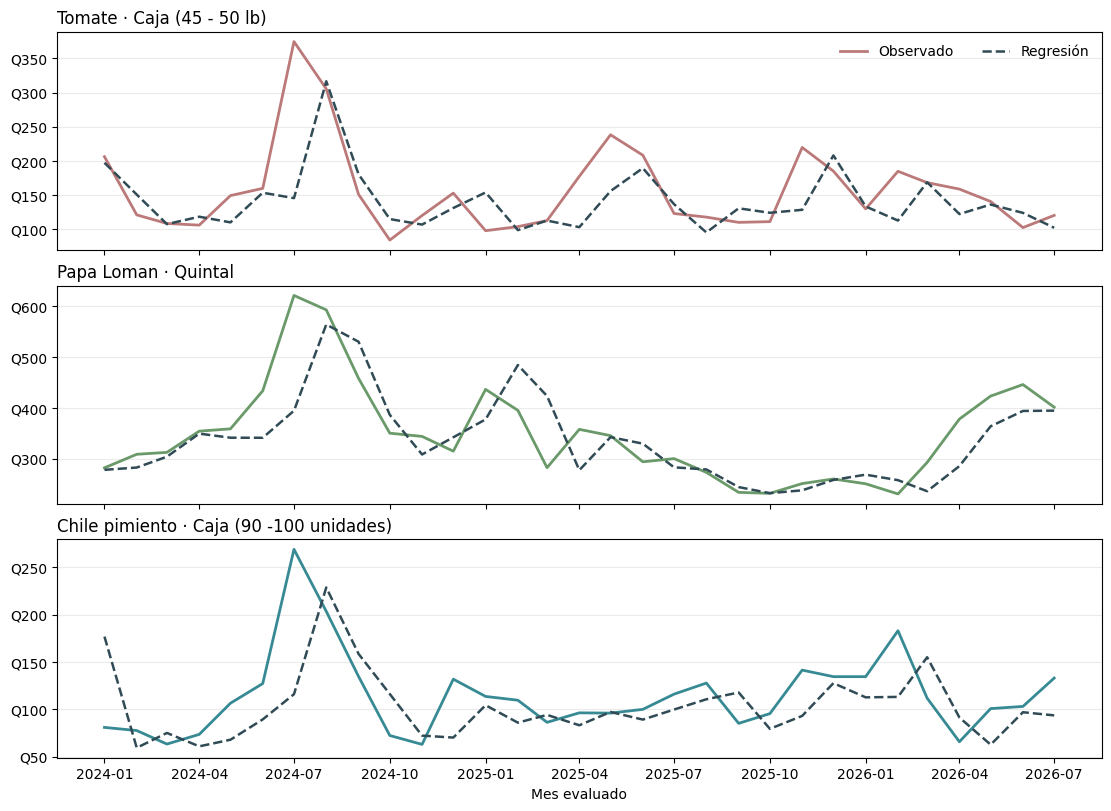

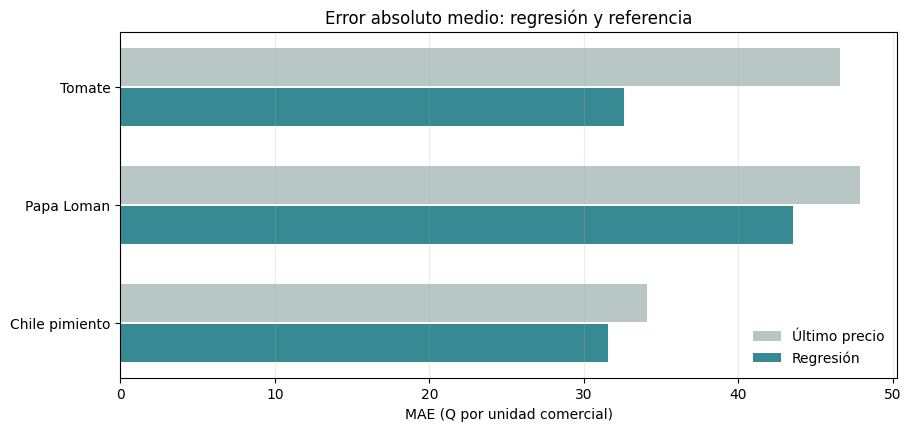

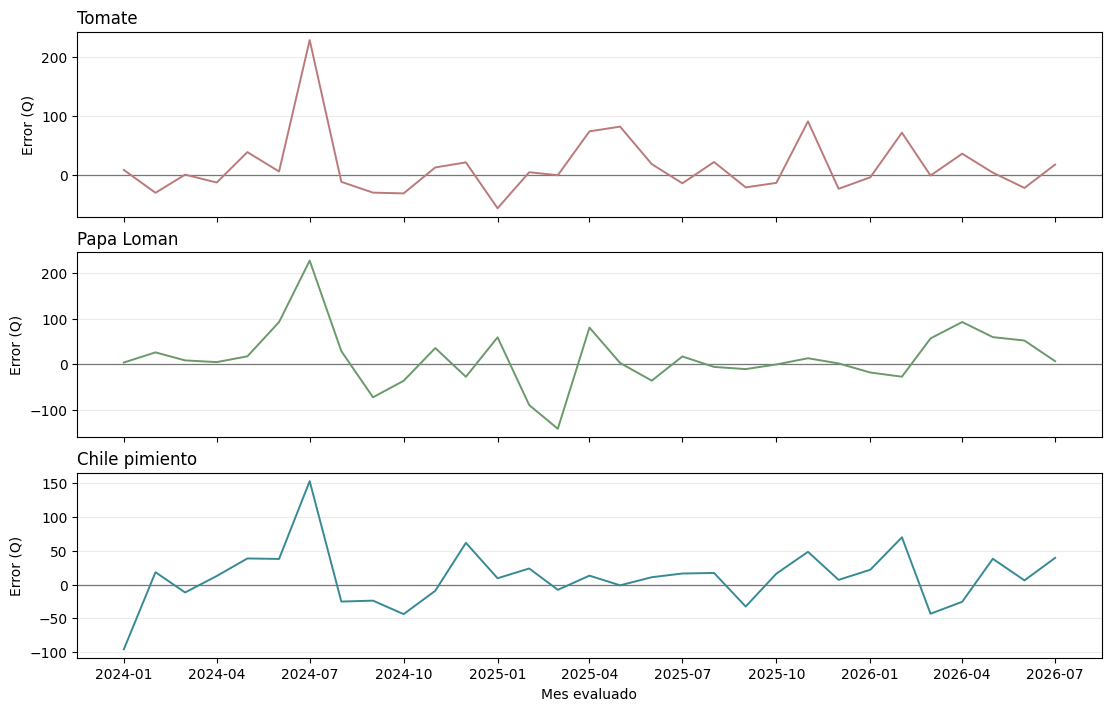

In [5]:
# Contrastamos el precio observado con el estimado para cada producto.
fig, ejes = plt.subplots(3, 1, figsize=(11, 8), sharex=True, layout='constrained')
for ax, producto in zip(ejes, ORDEN):
    p = predicciones.loc[predicciones['Producto'].eq(producto)]
    ax.plot(p['Fecha'], p['Precio_real_Q'], label='Observado', color=COLORES[producto], lw=2)
    ax.plot(p['Fecha'], p['Precio_estimado_Q'], label='Regresión', color='#304B55', ls='--', lw=1.8)
    ax.set_title(f'{producto} · {p["Medida"].iloc[0]}', loc='left')
    ax.yaxis.set_major_formatter(FMT_Q)
    ax.grid(axis='y', alpha=.25)
ejes[0].legend(frameon=False, ncol=2)
ejes[-1].set_xlabel('Mes evaluado')
grafica(fig, '03_reales_vs_estimados.png')

# Comparamos el error de la regresión con el de usar el último precio.
fig, ax = plt.subplots(figsize=(9, 4.2), layout='constrained')
y = np.arange(len(ORDEN))
ax.barh(y - .17, resumen['MAE_referencia_Q'], height=.32, label='Último precio', color='#B8C7C5')
ax.barh(y + .17, resumen['MAE_Q'], height=.32, label='Regresión', color='#378A94')
ax.set_yticks(y, resumen['Producto'])
ax.invert_yaxis()
ax.set_xlabel('MAE (Q por unidad comercial)')
ax.set_title('Error absoluto medio: regresión y referencia')
ax.grid(axis='x', alpha=.25)
ax.legend(frameon=False)
grafica(fig, '03_comparacion_MAE.png')

# Revisamos cómo se distribuyen los errores a lo largo de los meses.
fig, ejes = plt.subplots(3, 1, figsize=(11, 7), sharex=True, layout='constrained')
for ax, producto in zip(ejes, ORDEN):
    p = predicciones.loc[predicciones['Producto'].eq(producto)]
    ax.axhline(0, color='#777', lw=.9)
    ax.plot(p['Fecha'], p['Error_Q'], color=COLORES[producto], lw=1.4)
    ax.set_title(producto, loc='left')
    ax.set_ylabel('Error (Q)')
    ax.grid(axis='y', alpha=.25)
ejes[-1].set_xlabel('Mes evaluado')
grafica(fig, '03_errores.png')

## 6. Estimación posterior al último mes registrado

In [6]:
# Con el historial disponible estimamos el mes posterior al último registro.
filas_futuro = []
for producto in ORDEN:
    historico = datos.loc[datos['Producto_corto'].eq(producto)].sort_values('Fecha')
    d = modelables.loc[modelables['Producto_corto'].eq(producto)]
    modelo = LinearRegression().fit(d[VARIABLES], d['Precio'])
    fecha = historico['Fecha'].max() + pd.offsets.MonthBegin(1)
    valores = historico['Precio'].to_numpy()
    entrada = {f'lag_{i}': valores[-i] for i in rezagos}
    entrada['mes_sin'] = np.sin(2 * np.pi * (fecha.month - 1) / 12)
    entrada['mes_cos'] = np.cos(2 * np.pi * (fecha.month - 1) / 12)
    pronostico = modelo.predict(pd.DataFrame([entrada])[VARIABLES])[0]
    filas_futuro.append((producto, historico['Medida'].iloc[0], fecha, float(pronostico)))
    nombre = {'Tomate': 'tomate', 'Papa Loman': 'papa_loman', 'Chile pimiento': 'chile_pimiento'}[producto]
    joblib.dump(modelo, MODELOS / f'03_regresion_multiple_{nombre}.joblib')

# Mostramos y guardamos las estimaciones para los tres productos.
futuro = pd.DataFrame(filas_futuro, columns=['Producto', 'Medida', 'Fecha', 'Estimacion_Q'])
assert futuro['Fecha'].eq(pd.Timestamp('2026-08-01')).all()
display(futuro.round(2))
tabla(futuro, '03_estimacion_agosto_2026.csv')

,Producto,Medida,Fecha,Estimacion_Q
0,Tomate,Caja (45 - 50 lb),2026-08-01,140.49
1,Papa Loman,Quintal,2026-08-01,347.39
2,Chile pimiento,Caja (90 -100 unidades),2026-08-01,120.93
